# Практикум: Базовая статистика для Data Analytics / BI

Этот ноутбук содержит 5 экспресс-задач.
В каждой задаче уже сгенерированы синтетические данные. Ваша цель — дописать код в местах, отмеченных `TODO`, и ответить на бизнес-вопросы.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройки для графиков
sns.set_theme(style="whitegrid")
np.random.seed(42)

## Тема 1. Описательная статистика и распределения
**Контекст:** Вы анализируете чеки покупок за день. Большинство покупок — это кофе и выпечка, но один клиент купил профессиональную кофемашину.

In [2]:
# Генерация данных: 19 чеков от 100 до 500 руб. и 1 чек на 100 000 руб.
normal_checks = np.random.randint(100, 500, 19)
outlier_check = np.array([100000])
checks = np.concatenate([normal_checks, outlier_check])
df_checks = pd.DataFrame({'amount_rub': checks})

print(df_checks)

    amount_rub
0          202
1          448
2          370
3          206
4          171
5          288
6          120
7          202
8          221
9          314
10         430
11         187
12         472
13         199
14         459
15         251
16         230
17         249
18         408
19      100000


In [8]:
# TODO: Рассчитайте среднее арифметическое, медиану и моду для столбца amount_rub
mean_val = df_checks['amount_rub'].mean()
median_val = df_checks['amount_rub'].median()
mode_val = df_checks['amount_rub'].mode().iloc[0] # Учтите, что мода может возвращать несколько значений (Series)

print(f"Среднее: {mean_val}")
print(f"Медиана: {median_val}")
print(f"Мода: {mode_val}")

Среднее: 5271.35
Медиана: 250.0
Мода: 202


**Бизнес-вопрос (Тема 1):**
*TODO: Напишите здесь, какое из этих значений лучше вывести на главный экран дашборда интернет-магазина как "Типичный чек за день" и почему?*

**Лучше вынести медиану. В данных есть выброс на 100 000 рублей, который сильно завышает среднее арифметическое. Мода тоже не лучший вариант. Медиана устойчива к выбросам и показывает реальную сумму, которую тратит типичный покупатель.**

## Тема 2. Выбросы: Поиск и обработка (Метод IQR)
**Контекст:** Логистический сервис анализирует время доставки (в минутах). В базу попали ошибочные значения (баги трекинга). Нужно отфильтровать аномалии.

In [10]:
# Генерация данных: 1000 нормальных доставок (30-90 мин) + 20 багов (например, -999 мин или 5000 мин)
delivery_times = np.concatenate([
    np.random.normal(60, 15, 1000),
    [-999]*10,
    [5000]*10
])
df_delivery = pd.DataFrame({'duration_min': delivery_times})
print(df_delivery)

      duration_min
0        44.526356
1        52.060526
2        69.280298
3        76.939867
4       104.475155
...            ...
1015   5000.000000
1016   5000.000000
1017   5000.000000
1018   5000.000000
1019   5000.000000

[1020 rows x 1 columns]


In [15]:
# TODO 1: Найдите Q1 (25-й перцентиль) и Q3 (75-й перцентиль)
q1 = df_delivery['duration_min'].quantile(0.25)
q3 = df_delivery['duration_min'].quantile(0.75)

# TODO 2: Рассчитайте межквартильный размах (IQR)
iqr = q3 - q1

# TODO 3: Рассчитайте нижнюю и верхнюю границы (Q1 - 1.5*IQR и Q3 + 1.5*IQR)
lower_bound = q1 - 1.5*iqr
upper_bound = q3 + 1.5*iqr

# TODO 4: Отфильтруйте df_delivery, оставив только нормальные значения
mask = (df_delivery['duration_min'] >= lower_bound) & (df_delivery['duration_min'] <= upper_bound)
df_clean = df_delivery[mask]

# Расчет процента отсеянных строк
dropped_percent = (1 - len(df_clean) / len(df_delivery)) * 100
print(f"Отсеяно выбросов: {dropped_percent:.1f}%")

Отсеяно выбросов: 2.5%


## Тема 3. Корреляция и причинно-следственные связи
**Контекст:** Вы изучаете статистику городских пожаров. Построен график зависимости между количеством вызванных пожарных машин и суммой ущерба.

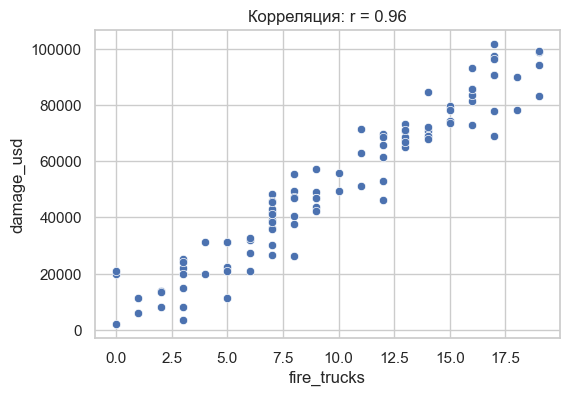

In [16]:
# Синтетические данные: Размер пожара (скрытый фактор - confounder) влияет и на число машин, и на ущерб
fire_severity = np.random.uniform(1, 10, 100)
fire_trucks = (fire_severity * 2 + np.random.normal(0, 1, 100)).astype(int)
damage_usd = fire_severity * 10000 + np.random.normal(0, 5000, 100)

df_fires = pd.DataFrame({
    'fire_trucks': fire_trucks,
    'damage_usd': damage_usd
})

# Построение графика
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df_fires, x='fire_trucks', y='damage_usd')
plt.title(f"Корреляция: r = {df_fires.corr().iloc[0,1]:.2f}")
plt.show()

**Бизнес-вопрос (Тема 3):**
Корреляция Пирсона показывает сильную прямую связь ($r > 0.9$).
*TODO: Верно ли утверждение «Чем больше пожарных машин приезжает, тем больший ущерб они наносят»? Какая скрытая переменная (Confounder) здесь присутствует?*

**Нет, не верно. Скрытая переменная - это серьезность пожара (fire_severity). По логике *большой пожар* наносит *большой ущерб и требует вызова большего количества пожарных машин*.**

**r=0.96 показывает лишь то, что эти два показателя меняются вместе, а действительно зависят они от скрытой переменной**

## Тема 4. Когортный анализ (Retention)
**Контекст:** Маркетинг предоставил готовую матрицу удержания (Retention Matrix) по месяцам. Вам нужно сделать выводы без написания кода.

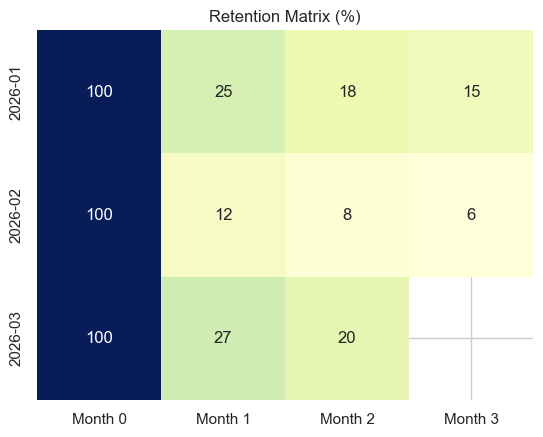

In [17]:
# Готовая матрица удержания в виде DataFrame
retention_matrix = pd.DataFrame({
    'Month 0': [100, 100, 100],
    'Month 1': [25, 12, 27],
    'Month 2': [18, 8, 20],
    'Month 3': [15, 6, np.nan]
}, index=['2026-01', '2026-02', '2026-03'])

# Тепловая карта для наглядности
sns.heatmap(retention_matrix, annot=True, fmt='g', cmap='YlGnBu', cbar=False)
plt.title("Retention Matrix (%)")
plt.show()

**Бизнес-вопросы (Тема 4):**
*TODO:*
1. *В какой когорте произошел резкий провал качества трафика (или сбой в продукте)?*
В когорте 2026-02 удержание на 1 месяц более чем в 2 раза ниже чем в аналогичный период других когорт. 
2. *Какой процент пользователей январской когорты ('2026-01') вернулся на 2-й месяц (Month 2)?*
18%  - строка 2026-01 и столбец Month 2

## Тема 5. RFM-анализ и сегментация
**Контекст:** Вы посчитали скоры R, F, M (от 1 до 3) для небольшой выборки клиентов. Теперь нужно разметить клиентов по бизнес-сегментам.

In [18]:
# Данные о клиентах (уже рассчитанные квантили 1-3)
# R: 3 = недавняя покупка. F: 3 = частые покупки. M: 3 = высокий чек.
df_rfm = pd.DataFrame({
    'client_id': [101, 102, 103, 104, 105],
    'R': [3, 1, 2, 1, 3],
    'F': [3, 3, 2, 1, 2],
    'M': [3, 2, 2, 1, 1]
})

In [21]:
# TODO: Напишите функцию категоризации или используйте np.select / df.apply

    # Логика:
    # 1. Если R=3, F=3, M=3 -> 'Champion'
    # 2. Если R<=1 и F>=2 -> 'At Risk'
    # 3. Все остальные -> 'Regular'
c = [(df_rfm['R'] == 3) & (df_rfm['F'] == 3) & (df_rfm['M'] == 3),
    (df_rfm['R'] <= 1) & (df_rfm['F'] >= 2)]
res = ['Champion', 'At Risk']
    
df_rfm['Segment'] = np.select(c, res, default='Regular')
display(df_rfm)

,client_id,R,F,M,Segment
0,101,3,3,3,Champion
1,102,1,3,2,At Risk
2,103,2,2,2,Regular
3,104,1,1,1,Regular
4,105,3,2,1,Regular
